# Lloyd Jones - Colibri Digital - Technical Assessment

## 0. Setup

### 0.1 Imports

In [558]:
import sys
from pathlib import Path
from zipfile import ZipFile

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

# This statement allows display of plots without asking to 
%matplotlib inline

print(f"Python {sys.version.split()[0]}")
print(f"pandas=={pd.__version__}")
print(f"numpy=={np.__version__}")
print(f"matplotlib=={matplotlib.__version__}")
print(f"seaborn=={sns.__version__}")

Python 3.14.10
pandas==3.1.0
numpy==2.5.4
matplotlib==3.11.2
seaborn==0.13.2


### 0.2 Settings and parameters

In [559]:
# Data files and outputs
ZIP_PATTERN = "data*.zip"
DATA_DIR = Path("data")
FILE_PATTERN = "data_group_*.csv"
EXPECTED_FILES = 3
OUTPUT_DIR = Path("output")

# Dataset structure
KEY_COLUMNS = ["timestamp", "turbine_id"]                              # identifiers for each reading
MEASUREMENT_COLUMNS = ["wind_speed", "wind_direction", "power_output"] # measurements for each reading
EXPECTED_COLUMNS = KEY_COLUMNS + MEASUREMENT_COLUMNS                   # all columns expected in the dataset

# Expected coverage: one reading per turbine per hour
EXPECTED_TURBINE_IDS = list(range(1, 16))                              # turbines 1 to 15
PERIOD_START = pd.Timestamp("2022-03-01 00:00")                        # start of the expected period
PERIOD_END = pd.Timestamp("2022-03-31 23:00")                          # end of the expected period
READING_FREQ = "h"                                                     # hourly

# Physically valid ranges (inclusive)
RATED_CAPACITY_MW = 5.0                                                # assumption: not given in the brief
VALID_RANGES = {
    "wind_speed": (0, 30),                                             # m/s; assumption for the upper limit
    "wind_direction": (0, 360),                                        # degrees
    "power_output": (0, RATED_CAPACITY_MW),                            # MW
}

# Anomaly detection
STD_THRESHOLD = 2  # flag turbines more than this many standard deviations from the day's mean

## 1. Load

### 1.1 Locate the data files

In [560]:
# Search the current folder for a ZIP file of the data
matching_zip_files = sorted(Path(".").glob(ZIP_PATTERN))

# Only extract the ZIP if the data folder does not already contain the CSV files
if list(DATA_DIR.glob(FILE_PATTERN)):
    print(f"CSV files already found in '{DATA_DIR}', so no ZIP extraction is needed.")
elif matching_zip_files:
    # Open the zip file in read mode ('r') and extract all contents into the data folder
    with ZipFile(matching_zip_files[0], 'r') as zip_data:
        zip_data.extractall(DATA_DIR)
    print(f"Extracted '{matching_zip_files[0]}' into '{DATA_DIR}'.")
else:
    print(f"No CSV files in '{DATA_DIR}' and no ZIP file matching '{ZIP_PATTERN}' were found.")

Extracted 'data (1) (1) (1) (1) (1).zip' into 'data'.


In [561]:
# Search the data folder for the CSV files, sorted so they always load in the same order
matching_data_files = sorted(DATA_DIR.glob(FILE_PATTERN))

# Display the results
print(f"Found {len(matching_data_files)} of {EXPECTED_FILES} expected CSV file(s):")
for file_path in matching_data_files:
    print(file_path)

# Stop if the number of files is not what was expected, as every later step depends on them
if len(matching_data_files) != EXPECTED_FILES:
    raise FileNotFoundError(f"Expected {EXPECTED_FILES} files matching '{FILE_PATTERN}' in '{DATA_DIR}', "
                            f"but found {len(matching_data_files)}.")

Found 3 of 3 expected CSV file(s):
data\data_group_1.csv
data\data_group_2.csv
data\data_group_3.csv


### 1.2 Import the data and check columns

In [562]:
all_data_dict = dict()

# Read each CSV file into a dataframe, stored under its file name without the extension (.csv)
for file_path in matching_data_files:
    all_data_dict[file_path.stem] = pd.read_csv(file_path)

In [563]:
# Check each file has exactly the expected columns, regardless of order
all_columns_match = True
for file_name, data in all_data_dict.items():
    if set(data.columns) != set(EXPECTED_COLUMNS):
        all_columns_match = False
        print(f"{file_name} has unexpected columns: {list(data.columns)}")

# Stop if any file has different columns, as the cleaning steps rely on these names
if all_columns_match:
    print(f"All files have the expected columns: {EXPECTED_COLUMNS}")
else:
    raise ValueError(f"Every file must have exactly these columns: {EXPECTED_COLUMNS}")

All files have the expected columns: ['timestamp', 'turbine_id', 'wind_speed', 'wind_direction', 'power_output']


### 1.3 Combine into one dataset

In [564]:
# Combine all dataframes into a single dataframe
combined_df = pd.concat(all_data_dict.values(), ignore_index=True)
print(f"Combined {len(all_data_dict)} files into {combined_df.shape[0]} rows.")

Combined 3 files into 11160 rows.


In [565]:
combined_df.info()  # Display the structure of the combined dataframe

<class 'pandas.DataFrame'>
RangeIndex: 11160 entries, 0 to 11159
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   timestamp       11160 non-null  str    
 1   turbine_id      11160 non-null  int64  
 2   wind_speed      11160 non-null  float64
 3   wind_direction  11160 non-null  int64  
 4   power_output    11160 non-null  float64
dtypes: float64(2), int64(2), str(1)
memory usage: 436.1 KB


## 2. Clean

In [566]:
# Copy the raw combined data so it stays unchanged for comparison
clean_df = combined_df.copy(deep=True)

# Record every check: what was found, how many rows it affected and what was done
cleaning_log = list()

print(f"Rows before cleaning: {clean_df.shape[0]}")

Rows before cleaning: 11160


### 2.1 Data types

In [567]:
# Convert each column to its correct type - values that cannot be converted become missing
for column in EXPECTED_COLUMNS:
    missing_before = clean_df[column].isnull().sum()

    if column == 'timestamp':
        # Convert 'timestamp' column to datetime format
        clean_df[column] = pd.to_datetime(clean_df[column], errors='coerce')
    else:
        clean_df[column] = pd.to_numeric(clean_df[column], errors='coerce')

    # Values that were present but could not be converted are now missing
    unconvertible = clean_df[column].isnull().sum() - missing_before
    print(f"{column}: {unconvertible} value(s) could not be converted")

    cleaning_log.append({'step': '2.1', 'issue': f"Unconvertible '{column}' values",
                        'rows_affected': unconvertible, 'action': 'Set to missing (handled in 2.2 or 2.5)'})

timestamp: 0 value(s) could not be converted
turbine_id: 0 value(s) could not be converted
wind_speed: 0 value(s) could not be converted
wind_direction: 0 value(s) could not be converted
power_output: 0 value(s) could not be converted


In [568]:
clean_df.info()  # Display the structure of the cleaned dataframe

<class 'pandas.DataFrame'>
RangeIndex: 11160 entries, 0 to 11159
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   timestamp       11160 non-null  datetime64[us]
 1   turbine_id      11160 non-null  int64         
 2   wind_speed      11160 non-null  float64       
 3   wind_direction  11160 non-null  int64         
 4   power_output    11160 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(2)
memory usage: 436.1 KB


### 2.2 Missing identifiers

In [569]:
# Find rows without a timestamp or turbine ID, as these cannot be placed in time or assigned to a turbine
missing_id_mask = clean_df[KEY_COLUMNS].isnull().any(axis=1)
print(f"Rows with a missing timestamp or turbine ID: {missing_id_mask.sum()}")

# Rule: remove these rows
clean_df = clean_df[~missing_id_mask]
cleaning_log.append({'step': '2.2', 'issue': 'Missing timestamp or turbine ID',
                    'rows_affected': missing_id_mask.sum(), 'action': 'Removed'})

# Find rows with a turbine ID that is not one of the expected turbines
unknown_turbine_mask = ~clean_df['turbine_id'].isin(EXPECTED_TURBINE_IDS)
print(f"Rows with an unknown turbine ID: {unknown_turbine_mask.sum()}")

if unknown_turbine_mask.sum() > 0:
    print(f"Unknown turbine IDs found: {sorted(clean_df.loc[unknown_turbine_mask, 'turbine_id'].unique().tolist())}")

# Rule: remove these rows, as they cannot be assigned to a known turbine
clean_df = clean_df[~unknown_turbine_mask]
cleaning_log.append({'step': '2.2', 'issue': 'Unknown turbine ID',
                    'rows_affected': unknown_turbine_mask.sum(), 'action': 'Removed'})

# Find rows with a timestamp outside the expected period
outside_period_mask = ~clean_df['timestamp'].between(PERIOD_START, PERIOD_END)
print(f"Rows with a timestamp outside {PERIOD_START} to {PERIOD_END}: {outside_period_mask.sum()}")

# Rule: remove these rows, as they do not belong to this month's data
clean_df = clean_df[~outside_period_mask]
cleaning_log.append({'step': '2.2', 'issue': 'Timestamp outside expected period',
                    'rows_affected': outside_period_mask.sum(), 'action': 'Removed'})

# Every remaining turbine ID is valid therefore store them as whole numbers
clean_df['turbine_id'] = clean_df['turbine_id'].astype(int)

Rows with a missing timestamp or turbine ID: 0
Rows with an unknown turbine ID: 0
Rows with a timestamp outside 2022-03-01 00:00:00 to 2022-03-31 23:00:00: 0


### 2.3 Duplicates

In [570]:
# Find exact duplicates: rows that are identical in every column
exact_duplicate_mask = clean_df.duplicated(keep='first')
print(f"Exact duplicate rows: {exact_duplicate_mask.sum()}")

# Rule: keep the first copy and remove the rest since the copies hold the same information
clean_df = clean_df[~exact_duplicate_mask]
cleaning_log.append({'step': '2.3', 'issue': 'Exact duplicate rows',
                    'rows_affected': exact_duplicate_mask.sum(), 'action': 'Removed extra copies'})

# Find conflicting duplicates: more than one row for the same turbine and hour however with different values
conflicting_mask = clean_df.duplicated(subset=KEY_COLUMNS, keep=False)
print(f"Rows sharing a timestamp and turbine ID but with different values: {conflicting_mask.sum()}")

if conflicting_mask.sum() > 0:
    print("Conflicting duplicates (same turbine and hour):")
    print(clean_df[conflicting_mask].sort_values(KEY_COLUMNS))

# Rule: remove every copy because there is no way to tell which reading is correct 
# also this would indicate a hardware issue that should be reported to the data provider
clean_df = clean_df[~conflicting_mask]
cleaning_log.append({'step': '2.3', 'issue': 'Conflicting duplicates (same turbine and hour)',
                    'rows_affected': conflicting_mask.sum(), 'action': 'Removed all copies'})

Exact duplicate rows: 0
Rows sharing a timestamp and turbine ID but with different values: 0


### 2.4 Out-of-range values

In [571]:
# Check each measurement column against its physically valid range from the settings in section 0.2
for column, (min_value, max_value) in VALID_RANGES.items():

    # Missing values are skipped here because they are handled in section 2.5
    out_of_range_mask = clean_df[column].notnull() & ~clean_df[column].between(min_value, max_value)
    print(f"{column}: {out_of_range_mask.sum()} value(s) outside {min_value} to {max_value}")

    if out_of_range_mask.sum() > 0:
        print(f"Rows with '{column}' outside {min_value} to {max_value}:")
        print(clean_df.loc[out_of_range_mask, KEY_COLUMNS + [column]])

    # Rule: keep the row, set the impossible value to missing and flag it so it can be traced
    clean_df[f"{column}_out_of_range"] = out_of_range_mask
    clean_df[column] = clean_df[column].mask(out_of_range_mask)

    cleaning_log.append({'step': '2.4', 'issue': f"'{column}' outside {min_value} to {max_value}",
                        'rows_affected': out_of_range_mask.sum(), 'action': 'Set to missing and flagged'})

wind_speed: 0 value(s) outside 0 to 30
wind_direction: 0 value(s) outside 0 to 360
power_output: 0 value(s) outside 0 to 5.0


### 2.5 Missing measurements

In [572]:
# Find rows with no measurements at all
empty_row_mask = clean_df[MEASUREMENT_COLUMNS].isnull().all(axis=1)
print(f"Rows with no measurements at all: {empty_row_mask.sum()}")

# Rule: remove these rows because they carry no information
clean_df = clean_df[~empty_row_mask]
cleaning_log.append({'step': '2.5', 'issue': 'Rows with no measurements',
                    'rows_affected': empty_row_mask.sum(), 'action': 'Removed'})

# Count the missing values left in each measurement column
missing_values = clean_df[MEASUREMENT_COLUMNS].isnull().sum()
print("Missing values in each measurement column after removal of rows with all measurements empty:")
print(missing_values)

# Rule: leave these remaining missing values because filling them would invent readings,
# and pandas skips missing values when calculating daily min, max and average
for column in MEASUREMENT_COLUMNS:
    cleaning_log.append({'step': '2.5', 'issue': f"Missing '{column}' values",
                        'rows_affected': missing_values[column], 'action': 'Left as missing'})

Rows with no measurements at all: 0
Missing values in each measurement column after removal of rows with all measurements empty:
wind_speed        0
wind_direction    0
power_output      0
dtype: int64


### 2.6 Cleaning log

In [573]:
# Sort the cleaned data and renumber the rows after the removals above
clean_df = clean_df.sort_values(KEY_COLUMNS).reset_index(drop=True)

print(f"Rows before cleaning: {combined_df.shape[0]}")
print(f"Rows after cleaning: {clean_df.shape[0]}")

# Combine every check into one table showing what was found and what was done
cleaning_log_df = pd.DataFrame(cleaning_log)
cleaning_log_df

Rows before cleaning: 11160
Rows after cleaning: 11160


,step,issue,rows_affected,action
0,2.1,Unconvertible 'timestamp' values,0,Set to missing (handled in 2.2 or 2.5)
1,2.1,Unconvertible 'turbine_id' values,0,Set to missing (handled in 2.2 or 2.5)
2,2.1,Unconvertible 'wind_speed' values,0,Set to missing (handled in 2.2 or 2.5)
3,2.1,Unconvertible 'wind_direction' values,0,Set to missing (handled in 2.2 or 2.5)
4,2.1,Unconvertible 'power_output' values,0,Set to missing (handled in 2.2 or 2.5)
5,2.2,Missing timestamp or turbine ID,0,Removed
6,2.2,Unknown turbine ID,0,Removed
7,2.2,Timestamp outside expected period,0,Removed
8,2.3,Exact duplicate rows,0,Removed extra copies
9,2.3,Conflicting duplicates (same turbine and hour),0,Removed all copies


## 3. Summarise

### 3.1 Daily min, max and average per turbine

In [574]:
# Add a column for the date (without time) to facilitate daily aggregation
clean_df['date'] = clean_df['timestamp'].dt.date

# Summarise each turbine for each day: minimum, maximum, and average power output
summary_df = clean_df.groupby(['turbine_id', 'date']).agg(
    min_power=('power_output', 'min'),
    max_power=('power_output', 'max'),
    avg_power=('power_output', 'mean'),
    n_readings=('power_output', 'count')
)

# Sort the summary dataframe by turbine_id and date for better readability with most recent dates at the top
summary_df = summary_df.sort_values(by=['turbine_id', 'date'], ascending=[True, False])

## 4. Flag anomalies

### 4.1 Daily turbine averages

In [575]:
# For each day, take every turbine's average power (one row per turbine per day) 
turbine_daily_avg = summary_df.reset_index()[["date", "turbine_id", "avg_power"]]

### 4.2 Daily mean and standard deviation

In [576]:
# For each day, work out the mean and standard deviation of the turbine averages
daily_groups = turbine_daily_avg.groupby("date")["avg_power"]

daily_stats = pd.DataFrame({
    "n_turbines": daily_groups.count(),
    "farm_mean": daily_groups.mean(),
    "farm_std": daily_groups.std(),
}).reset_index()

# Check every day has an average for each turbine so each mean and std is based on the expected 15 values (in the given case)
incomplete_days = daily_stats[daily_stats["n_turbines"] < len(EXPECTED_TURBINE_IDS)]
print(f"Days with fewer than {len(EXPECTED_TURBINE_IDS)} turbine averages: {len(incomplete_days)}")

Days with fewer than 15 turbine averages: 0


### 4.3 Flag turbines

In [577]:
# Flag any turbine whose average is more than 2 standard deviations from that day's mean
anomaly_df = turbine_daily_avg.merge(daily_stats, on="date", how="left")
anomaly_df["z_score"] = (anomaly_df["avg_power"] - anomaly_df["farm_mean"]) / anomaly_df["farm_std"]
anomaly_df["is_anomaly"] = anomaly_df["z_score"].abs() > STD_THRESHOLD

### 4.4 Show flagged turbines

In [578]:
# Show the flagged turbines and the days they were flagged on
flagged_df = anomaly_df[anomaly_df["is_anomaly"]].sort_values(["turbine_id", "date"])
print(f"Flagged {len(flagged_df)} of {len(anomaly_df)} turbine-days "
    f"(more than {STD_THRESHOLD} standard deviations from the day's mean).")
flagged_df[["turbine_id", "date", "avg_power", "farm_mean", "farm_std", "z_score"]].round(3)

Flagged 17 of 465 turbine-days (more than 2 standard deviations from the day's mean).


,turbine_id,date,avg_power,farm_mean,farm_std,z_score
24,1,2022-03-07,3.283,2.996,0.143,2.009
60,2,2022-03-02,2.467,3.024,0.225,-2.479
87,3,2022-03-06,3.300,3.007,0.135,2.167
65,3,2022-03-28,2.688,2.975,0.135,-2.133
113,4,2022-03-11,2.479,2.974,0.207,-2.387
104,4,2022-03-20,2.504,2.977,0.234,-2.016
98,4,2022-03-26,2.471,2.978,0.215,-2.355
204,7,2022-03-13,2.725,2.984,0.123,-2.107
244,8,2022-03-04,2.529,2.965,0.166,-2.627
264,9,2022-03-15,3.471,3.077,0.166,2.370


## 5. Save

### 5.1 Cleaned data

In [579]:
# Create the output folder if it does not already exist
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the cleaned readings, without the 'date' helper column added for the daily summary
clean_output_path = OUTPUT_DIR / 'turbine_readings_clean.csv'
clean_df.drop(columns=['date']).to_csv(clean_output_path, index=False)
print(f"Saved {clean_df.shape[0]} cleaned rows to '{clean_output_path}'")

# Save the cleaning log, so the checks and their outcomes can be reviewed alongside the data
log_output_path = OUTPUT_DIR / 'cleaning_log.csv'
cleaning_log_df.to_csv(log_output_path, index=False)
print(f"Saved the cleaning log to '{log_output_path}'")

Saved 11160 cleaned rows to 'output\turbine_readings_clean.csv'
Saved the cleaning log to 'output\cleaning_log.csv'


### 5.2 Daily summary with anomaly flags

In [580]:
# Add each turbine-day's anomaly result to the daily summary
summary_output_df = summary_df.reset_index().merge(
    anomaly_df[['turbine_id', 'date', 'farm_mean', 'farm_std', 'z_score', 'is_anomaly']],
    on=['turbine_id', 'date'],
    how='left'
)

# Round the calculated values to 3 decimal places for readability
summary_output_df = summary_output_df.round(3)

# Save the daily summary with anomaly flags
summary_output_path = OUTPUT_DIR / 'daily_turbine_summary.csv'
summary_output_df.to_csv(summary_output_path, index=False)
print(f"Saved {summary_output_df.shape[0]} turbine-days to '{summary_output_path}', "
    f"of which {summary_output_df['is_anomaly'].sum()} are flagged as anomalies")

print("First few rows of the daily summary with anomaly flags:")
summary_output_df.head()

Saved 465 turbine-days to 'output\daily_turbine_summary.csv', of which 17 are flagged as anomalies
First few rows of the daily summary with anomaly flags:


,turbine_id,date,min_power,max_power,avg_power,n_readings,farm_mean,farm_std,z_score,is_anomaly
0,1,2022-03-31,1.6,4.3,2.958,24,3.021,0.226,-0.275,False
1,1,2022-03-30,1.5,4.4,3.050,24,3.014,0.146,0.248,False
2,1,2022-03-29,1.5,4.5,3.129,24,2.971,0.197,0.804,False
3,1,2022-03-28,1.6,4.5,3.075,24,2.975,0.135,0.739,False
4,1,2022-03-27,1.7,4.4,3.100,24,3.027,0.130,0.559,False


## 6. Additional observations

### 6.1 Power distribution per turbine

In [581]:
# Describe the distribution of power output for each turbine
clean_df.groupby('turbine_id')[['power_output']].describe()

power_output                                               
                  count      mean       std  min    25%  50%  75%  max
turbine_id                                                            
1                 744.0  3.016398  0.857239  1.5  2.300  3.0  3.7  4.5
2                 744.0  2.983602  0.874523  1.5  2.200  3.0  3.7  4.5
3                 744.0  2.979973  0.862632  1.5  2.200  3.0  3.7  4.5
4                 744.0  2.946371  0.887031  1.5  2.200  2.9  3.7  4.5
5                 744.0  3.016532  0.865883  1.5  2.300  3.0  3.8  4.5
6                 744.0  2.983871  0.874113  1.5  2.200  3.0  3.7  4.5
7                 744.0  3.012634  0.876385  1.5  2.275  3.0  3.8  4.5
8                 744.0  2.984812  0.891759  1.5  2.200  2.9  3.8  4.5
9                 744.0  3.002823  0.874265  1.5  2.200  3.0  3.8  4.5
10                744.0  3.006048  0.866284  1.5  2.200  3.0  3.8  4.5
11                744.0  2.959140  0.868530  1.5  2.200  2.9  3.7  4.5
12                744.0  3.051210  0.861076  1.5  2.300  3.1  3.8  4.5
13                744.0  3.031317  0.877320  1.5  2.200  3.1  3.8  4.5
14                744.0  3.017742  0.857181  1.5  2.300  3.0  3.8  4.5
15                744.0  3.036425  0.853780  1.5  2.300  3.1  3.7  4.5

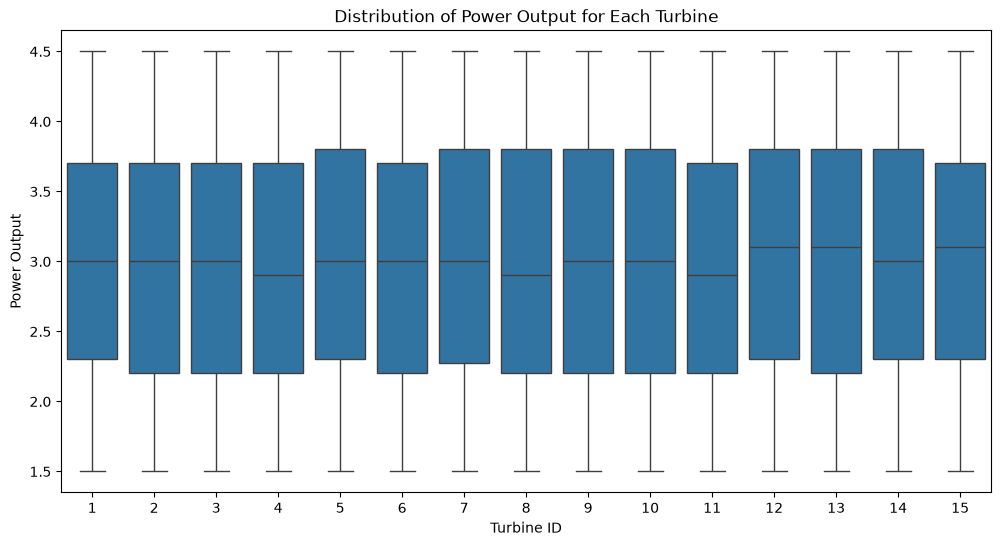

In [582]:
# Plot this description using seaborn's boxplot to visualise the distribution of power output for each turbine
plt.figure(figsize=(12, 6))
sns.boxplot(data=clean_df, x='turbine_id', y='power_output')
plt.title('Distribution of Power Output for Each Turbine')
plt.xlabel('Turbine ID')
plt.ylabel('Power Output')
plt.show()

### 6.2 Wind speed vs power

In [583]:
# Measure how closely power output follows wind speed, across all turbines and for each turbine
overall_correlation = clean_df['wind_speed'].corr(clean_df['power_output'])
print(f"Correlation between wind speed and power output (all turbines): {overall_correlation:.3f}")

turbine_correlations = dict()
for turbine_id, turbine_data in clean_df.groupby('turbine_id'):
    turbine_correlations[turbine_id] = turbine_data['wind_speed'].corr(turbine_data['power_output'])

print(f"Correlation for individual turbines ranges from {min(turbine_correlations.values()):.3f} "
    f"to {max(turbine_correlations.values()):.3f}")

Correlation between wind speed and power output (all turbines): -0.002
Correlation for individual turbines ranges from -0.077 to 0.067


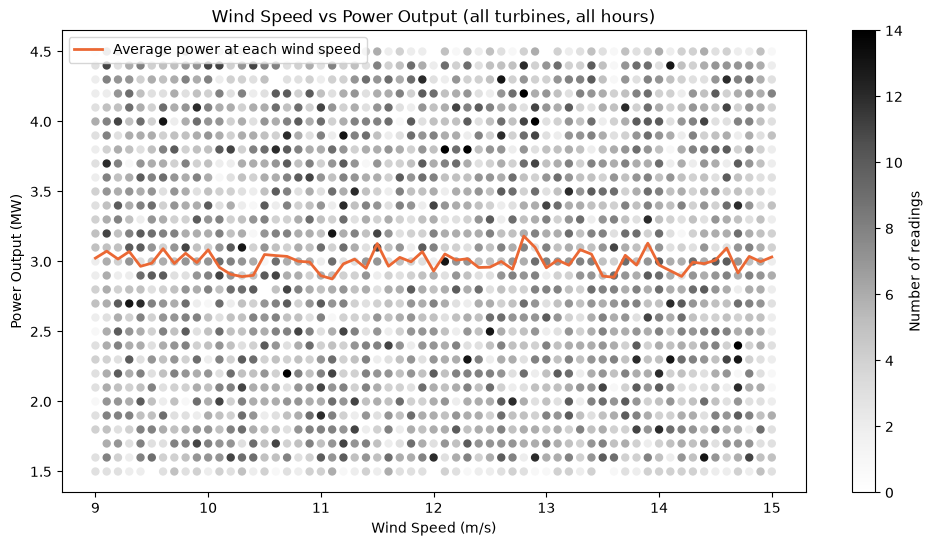

In [584]:
# Count how many readings share each combination of wind speed and power output
reading_counts = clean_df.groupby(['wind_speed', 'power_output']).size().reset_index(name='n_readings')

# Work out the average power output at each wind speed, to show the overall trend
avg_power_by_wind = clean_df.groupby('wind_speed')['power_output'].mean()

# Plot one dot per combination, shaded from light grey (few readings) to dark grey (many)
plt.figure(figsize=(12, 6))
dots = plt.scatter(reading_counts['wind_speed'], reading_counts['power_output'],
                c=reading_counts['n_readings'], cmap='Greys', vmin=0, s=25)
plt.colorbar(dots, label='Number of readings')

# Draw the average power at each wind speed in orange on top
plt.plot(avg_power_by_wind.index, avg_power_by_wind.values,
        color='#eb6834', linewidth=2, label='Average power at each wind speed')
plt.title('Wind Speed vs Power Output (all turbines, all hours)')
plt.xlabel('Wind Speed (m/s)')
plt.ylabel('Power Output (MW)')
plt.legend(loc='upper left')
plt.show()